In [96]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import precision_score, recall_score, roc_auc_score


In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Data preparation

In [4]:
# Check for data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
# Check the number of rows in the dataset
len(df)

5000

In [6]:
# Check the unique values in each column
for col in df.columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(f"Unique values: {df[col].nunique()}")
    print(f"Sample values: {df[col].unique()[:20]}")


Column: lead_source
Unique values: 5
Sample values: <StringArray>
['organic_search', 'social_media', 'referral', 'paid_ads', nan, 'events']
Length: 6, dtype: str

Column: industry
Unique values: 6
Sample values: <StringArray>
[   'technology',        'retail', 'manufacturing',     'education',
    'healthcare',             nan,       'finance']
Length: 7, dtype: str

Column: employment_status
Unique values: 4
Sample values: <StringArray>
['employed', 'student', nan, 'unemployed', 'self_employed']
Length: 5, dtype: str

Column: location
Unique values: 5
Sample values: <StringArray>
['europe', 'south_america', nan, 'north_america', 'africa', 'asia']
Length: 6, dtype: str

Column: annual_income
Unique values: 4313
Sample values: [88160. 72688. 44697.    nan 24062. 43841. 58738. 95059. 62565. 12000.
 43935. 80773. 47115. 62439. 59239. 37431. 83331. 49038. 50544. 31638.]

Column: number_of_courses_viewed
Unique values: 7
Sample values: [3 4 2 1 0 5 6]

Column: interaction_count
Unique valu

In [7]:
# Check for missing values in the dataset
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
# Fill missing values for string columns with 'NA'

# Identify categorical and numerical columns
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

numerical_cols = df.select_dtypes(
    include="number"
).columns

# Fill missing values
df[categorical_cols] = df[categorical_cols].fillna("NA")
df[numerical_cols] = df[numerical_cols].fillna(0.0)

# Confirm there are no missing values
print(df.isnull().sum().sum())

0


In [9]:
categorical_cols

Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str')

### Split the data

In [99]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [100]:
# Getting the target variable and features for training
y_train = df_train['converted'].values
X_train = df_train.drop(columns=['converted'])

# Getting the target variable and features for validation
y_val = df_val['converted'].values
X_val = df_val.drop(columns=['converted'])

### Question 1: ROC AUC feature importance

In [101]:
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

for col in numerical_cols:
    feature_scores = df_train[col]
    
    auc = roc_auc_score(y_train, feature_scores) 
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -feature_scores)
        
    print(f"{col}: {auc:.4f}")

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


### Question 2: Training the model

In [102]:
def train_predict(X_train, X_val, y_train, y_val, C=1.0):
    dv = DictVectorizer(sparse=False)

    X_train_dict = X_train.to_dict(orient='records')
    X_train_encoded = dv.fit_transform(X_train_dict)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train_encoded, y_train)

    X_val_dict = X_val.to_dict(orient='records')
    X_val_encoded = dv.transform(X_val_dict)

    y_val_pred = model.predict_proba(X_val_encoded)[:, 1]
    auc = roc_auc_score(y_val, y_val_pred)
    return auc, y_val_pred


auc , y_val_pred = train_predict(X_train, X_val, y_train, y_val)
print(f"AUC: {auc:.3f}")

AUC: 0.732


### Question 3: Precision and Recall

/home/gifty/ml-zoomcamp-2026/ml_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gifty/ml-zoomcamp-2026/ml_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gifty/ml-zoomcamp-2026/ml_venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

Threshold: 0.63


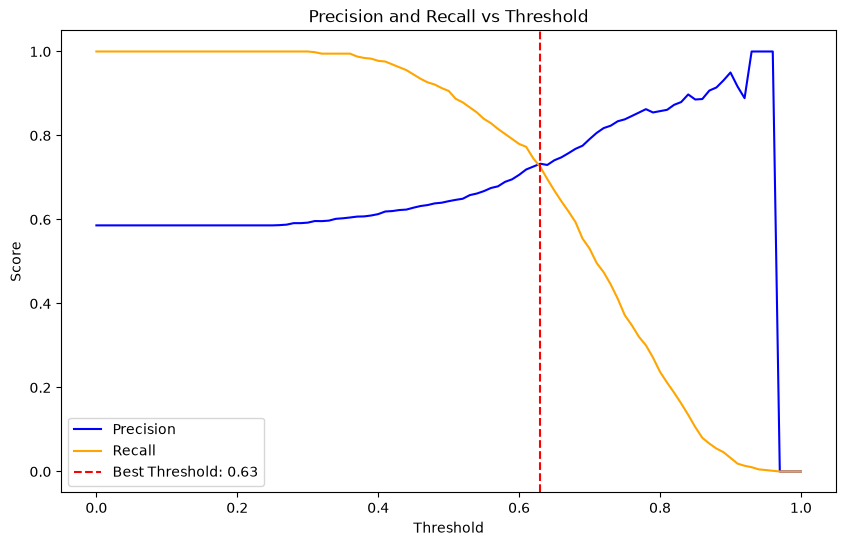

In [104]:
thresholds = np.linspace(0, 1, 101)
precision = []
recall = []

for threshold in thresholds:
    y_val_pred_binary = (y_val_pred >= threshold).astype(int)
    prec = precision_score(y_val, y_val_pred_binary)
    rec = recall_score(y_val, y_val_pred_binary)
    precision.append(prec)
    recall.append(rec)

differences = np.abs(np.array(precision) - np.array(recall))
valid = (np.array(precision) != 0) | (np.array(recall) != 0)

best_idx = np.argmin(np.where(valid, differences, np.inf))
print(f"Threshold: {thresholds[best_idx]:.2f}")


plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision, label='Precision', color='blue')
plt.plot(thresholds, recall, label='Recall', color='orange')
plt.axvline(x=thresholds[best_idx], color='red', linestyle='--', label=f'Best Threshold: {thresholds[best_idx]:.2f}')
plt.title('Precision and Recall vs Threshold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

### Question 4: F1 score

In [105]:
f1_scores = []
for p, r in zip(precision, recall):
    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * (p * r) / (p + r)
    f1_scores.append(f1)
    
best_idx = np.argmax(f1_scores)

print(f"Best threshold: {thresholds[best_idx]:.2f}")
print(f"Maximum F1: {f1_scores[best_idx]:.3f}")

Best threshold: 0.41
Maximum F1: 0.758


### Question 5: 5-Fold CV

In [106]:
scores = []
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
for train_idx, val_idx in kfold.split(df_full_train):
    
    train_fold = df_full_train.iloc[train_idx]
    val_fold = df_full_train.iloc[val_idx]
    
    y_train = train_fold["converted"].values
    y_val = val_fold["converted"].values
    
    X_train = train_fold.drop(columns=["converted"])
    X_val = val_fold.drop(columns=["converted"])
  
    auc, _ = train_predict(X_train, X_val, y_train, y_val)
    
    scores.append(auc)
    
print(round(np.std(scores), 3))


0.007


### Question 6: Hyperparameter Tuning

In [107]:
C_values = [0.000001, 0.001, 1]

for c in C_values:
    kfold = KFold( n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        
        train_fold = df_full_train.iloc[train_idx]
        val_fold = df_full_train.iloc[val_idx]

        y_train = train_fold["converted"].values
        y_val = val_fold["converted"].values

        X_train = train_fold.drop(columns=["converted"])
        X_val = val_fold.drop(columns=["converted"])

        auc, _ = train_predict(X_train, X_val, y_train, y_val, C=c)
        scores.append(auc)

    print(
        f"C={c}: mean AUC ={np.mean(scores):.3f}, "
        f"std= {np.std(scores):.3f}"
    )




C=1e-06: mean AUC =0.617, std= 0.019
C=0.001: mean AUC =0.749, std= 0.010
C=1: mean AUC =0.732, std= 0.007
